Saved: potf_fft.png


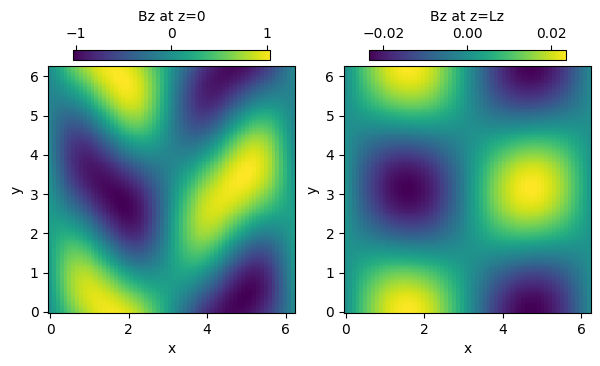

In [1]:
"""FFTによるCartesianポテンシャル磁場ソルバ."""

import numpy as np


def solve_potential_field_fft_cartesian_at_z(
    b0_grid: np.ndarray,
    lx: float,
    ly: float,
    lz: float,
    z: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """水平周期Cartesian領域のポテンシャル磁場を任意のz位置で評価する.

    Parameters
    ----------
    b0_grid
        shape=(ny, nx) の下端垂直磁場 Bz(x, y, z=0)。
    lx, ly, lz
        計算領域サイズ。
    z
        shape=(nz,) の評価位置。0 <= z <= lz を想定する。

    Returns
    -------
    psi
        shape=(nz, ny, nx) のスカラー磁気ポテンシャル。
    bx, by, bz
        shape=(nz, ny, nx) の磁場成分。
    """
    b0_grid = np.asarray(b0_grid, dtype=np.float64)
    z = np.asarray(z, dtype=np.float64)

    if z.ndim != 1:
        raise ValueError("z must be a one-dimensional array.")

    if np.any(z < 0.0) or np.any(z > lz):
        raise ValueError("z must satisfy 0 <= z <= lz.")

    ny, nx = b0_grid.shape
    nz = z.size

    kx = 2.0 * np.pi * np.fft.rfftfreq(nx, d=lx / nx)
    ky = 2.0 * np.pi * np.fft.fftfreq(ny, d=ly / ny)

    b0_hat = np.fft.rfft2(b0_grid)

    nkx = nx // 2 + 1

    psi_hat = np.zeros((nz, ny, nkx), dtype=np.complex128)
    bx_hat = np.zeros_like(psi_hat)
    by_hat = np.zeros_like(psi_hat)
    bz_hat = np.zeros_like(psi_hat)

    for j in range(ny):
        kyj = ky[j]

        for i in range(nkx):
            kxi = kx[i]
            k = np.sqrt(kxi**2 + kyj**2)

            b0_mode = b0_hat[j, i]

            if k == 0.0:
                # Mean vertical flux mode:
                #
                # Psi = B0_mean * (Lz - z)
                # Bz  = B0_mean
                psi_mode = b0_mode * (lz - z)
                bz_mode = np.full_like(z, b0_mode, dtype=np.complex128)
            else:
                # Stable expressions:
                #
                # sinh(k(L-z)) / cosh(kL)
                # = [exp(-kz) - exp(-k(2L-z))] / [1 + exp(-2kL)]
                #
                # cosh(k(L-z)) / cosh(kL)
                # = [exp(-kz) + exp(-k(2L-z))] / [1 + exp(-2kL)]
                e1 = np.exp(-k * z)
                e2 = np.exp(-k * (2.0 * lz - z))
                den = 1.0 + np.exp(-2.0 * k * lz)

                sinh_ratio = (e1 - e2) / den
                cosh_ratio = (e1 + e2) / den

                psi_mode = (b0_mode / k) * sinh_ratio
                bz_mode = b0_mode * cosh_ratio

            psi_hat[:, j, i] = psi_mode

            bx_hat[:, j, i] = -1j * kxi * psi_mode
            by_hat[:, j, i] = -1j * kyj * psi_mode
            bz_hat[:, j, i] = bz_mode

    psi = np.fft.irfft2(psi_hat, s=(ny, nx), axes=(1, 2))
    bx = np.fft.irfft2(bx_hat, s=(ny, nx), axes=(1, 2))
    by = np.fft.irfft2(by_hat, s=(ny, nx), axes=(1, 2))
    bz = np.fft.irfft2(bz_hat, s=(ny, nx), axes=(1, 2))

    return psi, bx, by, bz


def main():
    import matplotlib.pyplot as plt

    from botf import make_multimode_bottom_bz

    lx, ly, y, x, bz_bottom = make_multimode_bottom_bz(nx=64, ny=128)

    lz = 0.5 * lx 
    z = np.array([0.0, 0.1, 0.2, 0.5, 1.0]) * lz

    psi, bx, by, bz = solve_potential_field_fft_cartesian_at_z(
        b0_grid=bz_bottom,
        lx=lx,
        ly=ly, 
        lz=lz,
        z=z,
    )


    # ---- plot data ----#
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(7, 4))

    # plot bottom Bz
    ax = axs[0]
    im = ax.pcolormesh(y, x, bz[0])
    cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
    cb.set_label("Bz at z=0")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    ax.label_outer()

    # plot top Bz
    ax = axs[1]
    im = ax.pcolormesh(y, x, bz[-1])
    cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
    cb.set_label("Bz at z=Lz")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    ax.label_outer()

    fig_file = "potf_fft.png"
    plt.savefig(fig_file, dpi=150)
    print(f"Saved: {fig_file}")


if __name__ == "__main__":
    main()


In [ ]:
# -*- coding: utf-8 -*-
"""Current-free field PINNs: J = 0"""

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import botf
import potf_pinns


class PeriodicBNet(nn.Module):
    """
    B(x, y, z) for horizontally periodic magnetic field.

    The network directly outputs Bx, By, Bz.
    x and y are encoded using sin/cos to enforce horizontal periodicity.
    """

    def __init__(
        self,
        lx: float,
        ly: float,
        lz: float,
        width: int = 128,
        depth: int = 5,
    ):
        super().__init__()
        self.lx = lx
        self.ly = ly
        self.lz = lz

        in_dim = 5  # sin x, cos x, sin y, cos y, z
        layers = []
        layers.append(nn.Linear(in_dim, width))
        layers.append(nn.Tanh())
        for _ in range(depth - 1):
            layers.append(nn.Linear(width, width))
            layers.append(nn.Tanh())
        layers.append(nn.Linear(width, 3))  # Bx, By, Bz
        self.net = nn.Sequential(*layers)

    def forward(self, x, y, z):
        # 周期境界に対応するため、座標を三角関数で入力
        xx = 2.0 * torch.pi * x / self.lx
        yy = 2.0 * torch.pi * y / self.ly

        # zは[-1, 1]に正規化して入力
        zz = 2.0 * z / self.lz - 1.0

        inp = torch.cat(
            [torch.sin(xx), torch.cos(xx), torch.sin(yy), torch.cos(yy), zz],
            dim=-1,
        )
        return self.net(inp)


def grad(u, x):
    return torch.autograd.grad(
        u,
        x,
        grad_outputs=torch.ones_like(u),
        create_graph=True,
        retain_graph=True,
    )[0]


def curl_and_div(B, x, y, z):
    """Return J=curl(B) and div(B). mu0 is omitted."""
    bx = B[:, 0:1]
    by = B[:, 1:2]
    bz = B[:, 2:3]

    bx_x = grad(bx, x)
    bx_y = grad(bx, y)
    bx_z = grad(bx, z)

    by_x = grad(by, x)
    by_y = grad(by, y)
    by_z = grad(by, z)

    bz_x = grad(bz, x)
    bz_y = grad(bz, y)
    bz_z = grad(bz, z)

    jx = bz_y - by_z
    jy = bx_z - bz_x
    jz = by_x - bx_y

    div_b = bx_x + by_y + bz_z

    J = torch.cat([jx, jy, jz], dim=-1)
    return J, div_b


def current_free_losses(model, x, y, z, eps=1.0e-8):
    B = model(x, y, z)
    J, div_b = curl_and_div(B, x, y, z)

    # |J|^2
    loss_current = torch.mean(torch.sum(J**2, dim=-1, keepdim=True))

    # |div B|^2
    loss_div = torch.mean(div_b**2)

    return loss_current, loss_div


def sample_periodic_b0(b0_grid, x, y, lx, ly):
    """
    Bilinear sampling from Bz bottom grid.

    b0_grid: tensor with shape (ny, nx)
    x, y: tensors with shape (n, 1), physical coordinates
    """

    ny, nx = b0_grid.shape

    # Periodic wrap
    xw = torch.remainder(x, lx)
    yw = torch.remainder(y, ly)

    # Convert to grid indices
    gx = xw / lx * nx
    gy = yw / ly * ny

    i0 = torch.floor(gx).long() % nx
    j0 = torch.floor(gy).long() % ny
    i1 = (i0 + 1) % nx
    j1 = (j0 + 1) % ny

    tx = gx - torch.floor(gx)
    ty = gy - torch.floor(gy)

    b00 = b0_grid[j0.squeeze(-1), i0.squeeze(-1)].unsqueeze(-1)
    b10 = b0_grid[j0.squeeze(-1), i1.squeeze(-1)].unsqueeze(-1)
    b01 = b0_grid[j1.squeeze(-1), i0.squeeze(-1)].unsqueeze(-1)
    b11 = b0_grid[j1.squeeze(-1), i1.squeeze(-1)].unsqueeze(-1)

    return (
        (1.0 - tx) * (1.0 - ty) * b00
        + tx * (1.0 - ty) * b10
        + (1.0 - tx) * ty * b01
        + tx * ty * b11
    )


def make_points(n, lx, ly, lz, device):
    x = lx * torch.rand(n, 1, device=device, requires_grad=True)
    y = ly * torch.rand(n, 1, device=device, requires_grad=True)
    z = lz * torch.rand(n, 1, device=device, requires_grad=True)
    return x, y, z


def make_points_near_top(n, lx, ly, lz, device, thickness=0.2):
    x = lx * torch.rand(n, 1, device=device, requires_grad=True)
    y = ly * torch.rand(n, 1, device=device, requires_grad=True)

    # z in [(1-thickness)*lz, lz]
    z = lz * (1.0 - thickness * torch.rand(n, 1, device=device))
    z.requires_grad_(True)

    return x, y, z


def train(
    b0_grid,
    lx,
    ly,
    lz,
    steps=20000,
    n_pde=4096,
    n_bc=2048,
    lr=1.0e-3,
    T_max=3000,
    eta_min=1e-5,
    device="cuda",
):
    b0_grid = torch.as_tensor(b0_grid, dtype=torch.float32, device=device)

    model = PeriodicBNet(lx=lx, ly=ly, lz=lz).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt,
        T_max=T_max,
        eta_min=eta_min,
    )

    for step in range(steps):
        opt.zero_grad()

        # ---- Interior current-free and divB losses ----
        x, y, z = make_points(n_pde, lx, ly, lz, device)
        loss_current, loss_div = current_free_losses(model, x, y, z)

        # 上端付近の内部点を少し増やす
        xti, yti, zti = make_points_near_top(n_pde // 2, lx, ly, lz, device)
        loss_current_top_i, loss_div_top_i = current_free_losses(
            model, xti, yti, zti
        )

        loss_current = loss_current + loss_current_top_i
        loss_div = loss_div + loss_div_top_i

        # ---- Bottom boundary: Bz = B0 ----
        xb = lx * torch.rand(n_bc, 1, device=device, requires_grad=True)
        yb = ly * torch.rand(n_bc, 1, device=device, requires_grad=True)
        zb = torch.zeros(n_bc, 1, device=device, requires_grad=True)

        B_bottom_pred = model(xb, yb, zb)
        bz_bottom_pred = B_bottom_pred[:, 2:3]

        bz_bottom_target = sample_periodic_b0(b0_grid, xb, yb, lx, ly)
        loss_bottom_bz = torch.mean((bz_bottom_pred - bz_bottom_target) ** 2)

        # ---- Top boundary regularization ----
        xt = lx * torch.rand(n_bc, 1, device=device, requires_grad=True)
        yt = ly * torch.rand(n_bc, 1, device=device, requires_grad=True)
        zt = lz * torch.ones(n_bc, 1, device=device, requires_grad=True)

        B_top = model(xt, yt, zt)
        bx_top = B_top[:, 0:1]
        by_top = B_top[:, 1:2]

        # 上端では水平磁場を弱く消す
        loss_top_horizontal = torch.mean(bx_top**2 + by_top**2)

        # ---- Total loss ----
        loss = (
            1.0 * loss_current
            + 1.0 * loss_div
            + 10.0 * loss_bottom_bz
            + 0.1 * loss_top_horizontal
        )

        loss.backward()
        opt.step()
        scheduler.step()
        if step % 500 == 0:
            print(
                step,
                {
                    "loss": float(loss.detach().cpu()),
                    "current": float(loss_current.detach().cpu()),
                    "divB": float(loss_div.detach().cpu()),
                    "bottom_bz": float(loss_bottom_bz.detach().cpu()),
                    "top_h": float(loss_top_horizontal.detach().cpu()),
                },
            )

    return model


@torch.no_grad()
def evaluate_field(model, x1d, y1d, z1d, device="cuda"):
    """
    Returns Bx, By, Bz on meshgrid with shape (nz, ny, nx).
    """
    X, Y, Z = torch.meshgrid(
        torch.as_tensor(x1d, dtype=torch.float32, device=device),
        torch.as_tensor(y1d, dtype=torch.float32, device=device),
        torch.as_tensor(z1d, dtype=torch.float32, device=device),
        indexing="xy",
    )

    x = X.reshape(-1, 1)
    y = Y.reshape(-1, 1)
    z = Z.reshape(-1, 1)

    B = model(x, y, z)

    nx = len(x1d)
    ny = len(y1d)
    nz = len(z1d)

    bx = B[:, 0].reshape(ny, nx, nz).permute(2, 0, 1).detach().cpu()
    by = B[:, 1].reshape(ny, nx, nz).permute(2, 0, 1).detach().cpu()
    bz = B[:, 2].reshape(ny, nx, nz).permute(2, 0, 1).detach().cpu()

    return bx, by, bz


def evaluate_residuals(model, x1d, y1d, z1d, device="cuda"):
    """
    Evaluate |J x B| and divB on a grid.
    """
    X, Y, Z = torch.meshgrid(
        torch.as_tensor(x1d, dtype=torch.float32, device=device),
        torch.as_tensor(y1d, dtype=torch.float32, device=device),
        torch.as_tensor(z1d, dtype=torch.float32, device=device),
        indexing="xy",
    )

    x = X.reshape(-1, 1).detach().requires_grad_(True)
    y = Y.reshape(-1, 1).detach().requires_grad_(True)
    z = Z.reshape(-1, 1).detach().requires_grad_(True)

    B = model(x, y, z)
    J, div_b = curl_and_div(B, x, y, z)
    j_cross_b = torch.cross(J, B, dim=-1)

    nx = len(x1d)
    ny = len(y1d)
    nz = len(z1d)

    jxb_abs = torch.sqrt(torch.sum(j_cross_b**2, dim=-1))
    div_b = div_b[:, 0]

    jxb_abs = jxb_abs.reshape(ny, nx, nz).permute(2, 0, 1).detach().cpu()
    div_b = div_b.reshape(ny, nx, nz).permute(2, 0, 1).detach().cpu()

    return jxb_abs, div_b


device: cuda
0 {'loss': 3.0361979007720947, 'current': 0.0017106191953644156, 'divB': 0.0004587707226164639, 'bottom_bz': 0.30336669087409973, 'top_h': 0.003616538131609559}
500 {'loss': 0.011989466845989227, 'current': 0.006147151812911034, 'divB': 0.003083321964368224, 'bottom_bz': 0.00027089723153039813, 'top_h': 0.000500204972922802}
1000 {'loss': 0.004563807509839535, 'current': 0.001962608192116022, 'divB': 0.0019376848358660936, 'bottom_bz': 6.47613633191213e-05, 'top_h': 0.00015900732250884175}
1500 {'loss': 0.001993116457015276, 'current': 0.0008111505885608494, 'divB': 0.0008344051893800497, 'bottom_bz': 3.415991523070261e-05, 'top_h': 5.9617304941639304e-05}
2000 {'loss': 0.001020665979012847, 'current': 0.0003878635761793703, 'divB': 0.00042015835060738027, 'bottom_bz': 2.070328628178686e-05, 'top_h': 5.6111992307705805e-05}
2500 {'loss': 0.0007800295134074986, 'current': 0.0003260079538449645, 'divB': 0.0002743822697084397, 'bottom_bz': 1.7436039343010634e-05, 'top_h': 5.2

OutOfMemoryError: CUDA out of memory. Tried to allocate 128.00 MiB. GPU 0 has a total capacity of 23.56 GiB of which 113.75 MiB is free. Process 1765051 has 12.50 GiB memory in use. Process 1765067 has 10.93 GiB memory in use. Of the allocated memory 10.60 GiB is allocated by PyTorch, and 30.36 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

device: cuda
0 {'loss': 3.1037869453430176, 'current': 0.002549201250076294, 'divB': 0.0021590483374893665, 'bottom_bz': 0.3098565936088562, 'top_h': 0.005126039497554302}
500 {'loss': 0.011344682425260544, 'current': 0.004618553444743156, 'divB': 0.0032509174197912216, 'bottom_bz': 0.00034409601357765496, 'top_h': 0.0003425090399105102}
1000 {'loss': 0.00356493191793561, 'current': 0.0012592740822583437, 'divB': 0.0013759653083980083, 'bottom_bz': 9.078095172299072e-05, 'top_h': 0.00021883119188714772}
1500 {'loss': 0.0016093463636934757, 'current': 0.0006336456281132996, 'divB': 0.000724754121620208, 'bottom_bz': 2.382628372288309e-05, 'top_h': 0.00012683751992881298}
2000 {'loss': 0.0010859871981665492, 'current': 0.00045007470180280507, 'divB': 0.0004701470024883747, 'bottom_bz': 1.562089346407447e-05, 'top_h': 9.556637814966962e-05}
2500 {'loss': 0.0008489077445119619, 'current': 0.00036105135222896934, 'divB': 0.0003626799152698368, 'bottom_bz': 1.157199039880652e-05, 'top_h': 9.

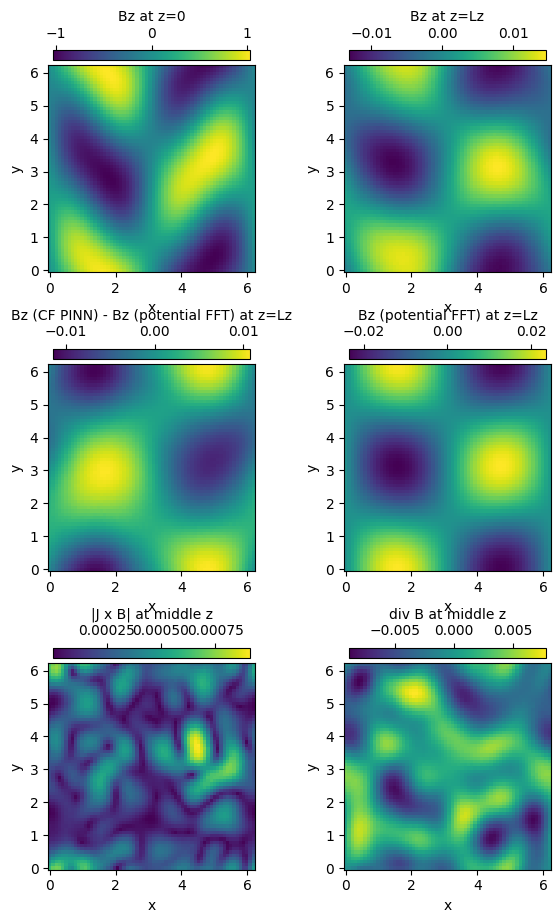

In [23]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# domain
lx, ly, x, y, b0 = botf.make_multimode_bottom_bz()

# size of vertical domain
lz = 0.5 * lx

# train
model = train(
    b0_grid=b0,
    lx=lx,
    ly=ly,
    lz=lz,
    steps=10000,
    n_pde=4096,
    n_bc=1024,
    lr=1.0e-3,
    T_max=3000,
    eta_min=1e-5,
    device=device,
)

# evaluate field
z = np.linspace(0.0, lz, len(x))

_, _, bz = evaluate_field(model, x, y, z, device=device)

# potential-field reference from FFT
_, _, _, bz_ref = potf_pinns.solve_potential_field_fft_cartesian_at_z(
    b0_grid=b0,
    lx=lx,
    ly=ly,
    lz=lz,
    z=z,
)

# residuals
jxb_abs, div_b = evaluate_residuals(model, x, y, z, device=device)

# ---- plot data ----
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(7, 11))

# plot bottom Bz
ax = axs[0, 0]
im = ax.pcolormesh(x, y, bz[0].numpy(), shading="auto")
cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
cb.set_label("Bz at z=0")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.label_outer()

# plot top Bz
ax = axs[0, 1]
im = ax.pcolormesh(x, y, bz[-1].numpy(), shading="auto")
cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
cb.set_label("Bz at z=Lz")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.label_outer()

# plot top Bz - potential reference
ax = axs[1, 0]
im = ax.pcolormesh(x, y, (bz[-1] - bz_ref[-1]).numpy(), shading="auto")
cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
cb.set_label("Bz (CF PINN) - Bz (potential FFT) at z=Lz")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.label_outer()

# plot potential reference top Bz
ax = axs[1, 1]
im = ax.pcolormesh(x, y, bz_ref[-1], shading="auto")
cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
cb.set_label("Bz (potential FFT) at z=Lz")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.label_outer()

# plot |J x B| at middle height
iz = len(z) // 2
ax = axs[2, 0]
im = ax.pcolormesh(x, y, jxb_abs[iz].numpy(), shading="auto")
cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
cb.set_label("|J x B| at middle z")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.label_outer()

# plot div B at middle height
ax = axs[2, 1]
im = ax.pcolormesh(x, y, div_b[iz].numpy(), shading="auto")
cb = fig.colorbar(im, location="top", pad=0.02, shrink=0.8)
cb.set_label("div B at middle z")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.label_outer()

fig_file = "cff_pinns.png"
plt.savefig(fig_file, dpi=150)
print(f"Saved: {fig_file}")

# save model
pt_file = "cff_pinns.pt"
torch.save(model.state_dict(), pt_file)
print(f"Saved: {pt_file}")


In [24]:
print(bz.shape)

torch.Size([64, 64, 64])
